# Which test images are hard for the U-Net?

**Dinesh Swaminathan** · small extra analysis · no GPU needed (about 1 minute)

Question: the pretrained U-Net scores Dice 0.862 on average, but some test images score
below 0.5. Do the hard images have something in common? We check three simple properties
of each test image:

1. **Polyp size**: share of the image that is polyp.
2. **Brightness contrast**: how much brighter the polyp is than the bowel wall
   (Lab lightness L, polyp mean minus wall mean). The baseline relies on this.
3. **Later batch**: the 23 test images whose file names start with `cjyz`, `cjz1` or `ck2`.

Input: `results/C1_dice_per_image.json` (Dice per test image, made by notebook 03), so
nothing is trained here.

In [1]:
import os, sys, json
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
if os.path.basename(os.getcwd()) == "dinesh":
    os.chdir("..")
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py
sys.path.insert(0, "src")

import numpy as np, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from data import load_resized, read_split
from baseline import lightness

names = read_split("test")
dice = json.load(open("results/C1_dice_per_image.json"))
unet = np.array(dice["pretrained"])        # mean of the 3 seeds, one value per test image
print(len(names), "test images, mean Dice", round(unet.mean(), 3))

120 test images, mean Dice 0.862


## 1 · Measure the three properties

In [2]:
size, contrast, later = [], [], []
for name in names:
    image, mask = load_resized(name, 256)
    light = lightness(image)
    view = image.max(axis=2) > 30                     # inside the endoscope view
    polyp = mask == 1
    wall = view & ~polyp
    size.append(polyp.mean())
    contrast.append(light[polyp].mean() - light[wall].mean())
    later.append(name[:4] in ("cjyz", "cjz1", "ck23", "ck2b", "ck2d"))
size, contrast, later = np.array(size), np.array(contrast), np.array(later)

## 2 · Does Dice go with size or contrast?
Spearman correlation: +1 = always goes up together, 0 = no relation, −1 = opposite.

Dice vs polyp size:           r = +0.18  (p = 0.055)
Dice vs brightness contrast:  r = +0.06  (p = 0.535)
later batch: Dice 0.809 (n=23)  vs  rest 0.874

hard images (Dice < 0.5): 7
  polyp size     median 25.3%   (all images 11.7%)
  contrast       median +48.6   (all images +30.9)
  later batch    3 of 7


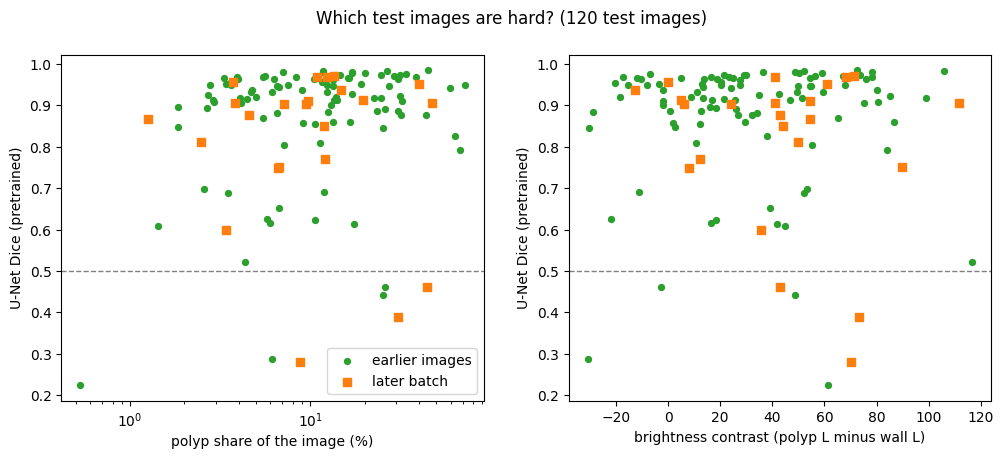

In [3]:
r_size, p_size = spearmanr(size, unet)
r_con, p_con = spearmanr(contrast, unet)
print(f"Dice vs polyp size:           r = {r_size:+.2f}  (p = {p_size:.3f})")
print(f"Dice vs brightness contrast:  r = {r_con:+.2f}  (p = {p_con:.3f})")
print(f"later batch: Dice {unet[later].mean():.3f} (n={later.sum()})  vs  rest {unet[~later].mean():.3f}")

hard = unet < 0.5
print(f"\nhard images (Dice < 0.5): {hard.sum()}")
print(f"  polyp size     median {np.median(size[hard]):.1%}   (all images {np.median(size):.1%})")
print(f"  contrast       median {np.median(contrast[hard]):+.1f}   (all images {np.median(contrast):+.1f})")
print(f"  later batch    {later[hard].sum()} of {hard.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, x, label in [(axes[0], size * 100, "polyp share of the image (%)"),
                     (axes[1], contrast, "brightness contrast (polyp L minus wall L)")]:
    ax.scatter(x[~later], unet[~later], s=18, color="tab:green", label="earlier images")
    ax.scatter(x[later], unet[later], s=28, color="tab:orange", marker="s", label="later batch")
    ax.axhline(0.5, color="grey", ls="--", lw=1)
    ax.set_xlabel(label); ax.set_ylabel("U-Net Dice (pretrained)")
axes[0].set_xscale("log"); axes[0].legend()
fig.suptitle("Which test images are hard? (120 test images)")
fig.savefig("results/D1_hard_images.png", dpi=150, bbox_inches="tight"); plt.show()

## 3 · What this means

Write 2–3 sentences in your own words after running it (this goes into the summary file):

In [4]:
summary = f"""# D1 · Which test images are hard? (Dinesh Swaminathan)

Pretrained U-Net, 120 test images.
- Dice vs polyp size: Spearman r = {r_size:+.2f} (p = {p_size:.3f})
- Dice vs brightness contrast: Spearman r = {r_con:+.2f} (p = {p_con:.3f})
- Later batch: Dice {unet[later].mean():.3f} (n = {later.sum()}) vs rest {unet[~later].mean():.3f}
- Hard images (Dice < 0.5): {hard.sum()}; median polyp size {np.median(size[hard]):.1%} (all: {np.median(size):.1%}); median contrast {np.median(contrast[hard]):+.1f} (all: {np.median(contrast):+.1f}); {later[hard].sum()} from the later batch
"""
open("results/D1_summary.md", "w", encoding="utf-8").write(summary); print(summary)

# D1 · Which test images are hard? (Dinesh Swaminathan)

Pretrained U-Net, 120 test images.
- Dice vs polyp size: Spearman r = +0.18 (p = 0.055)
- Dice vs brightness contrast: Spearman r = +0.06 (p = 0.535)
- Later batch: Dice 0.809 (n = 23) vs rest 0.874
- Hard images (Dice < 0.5): 7; median polyp size 25.3% (all: 11.7%); median contrast +48.6 (all: +30.9); 3 from the later batch

